# Lab 1 — Pipe flow and pump selection

Design a water-transfer line between two open tanks. Select a pipe and pump operating speed, then defend the energy implications.

**Completed solution**

**Instructor solution — completed reference notebook.**

I expect larger pipes to reduce hydraulic losses, but the least-electricity choice need not minimize total cost. Higher flow and higher static head will test different pump arrangements.

All exercises, including the small-change example and optional extension, are answered below. Use the matching `helpers.py` from this folder. Stage counts follow the student notebook conventions.

**Reading the answers:** The written interpretations refer to the printed default settings. Changing a setting updates calculated outputs when rerun, but does not automatically rewrite the prose. Alternative feasible choices can be valid when supported by evidence.

## Design workshop: run → compare → decide

All calculations and plots are supplied. Edit only **DESIGN SETTINGS**, then
rerun that section and the sections below it. Write engineering decisions using
numbers and units. No algorithm writing is required. This edition compares
electrical energy at equal delivery, includes illustrative pipe costs, and
treats series/parallel pumps as a core task.

Six-hour budget: setup 30 min; curve/energy review 60 min; fixed-duty diameter
comparison 75 min; costs and robustness 90 min; pump arrangements including a
break 60 min; final recommendation 45 min. The small worked example belongs
within the curve/energy review. Paired-pump curves are idealized screening tools.


**Time budget: 6 hours, including a short break and submission.** Work in pairs,
but both partners must be able to explain every figure and calculation.
Prerequisites: material and energy balances, algebra, and reading tables and plots. No Python programming is required.
Use SI units unless explicitly stated. All case data are synthetic teaching values,
not measurements or validated equipment specifications.

Submit this notebook with outputs and a short engineering recommendation (300–500 words).
Include assumptions, a labelled flowsheet, equations, units, balance checks,
at least one sensitivity plot, and a discussion of model limitations.
Optional extensions are outside the six-hour budget.

## 1. Setup and prediction — 30 minutes
Before computing, sketch the apparatus and predict which parameter most strongly
affects its size or energy demand. Explain your reasoning in two sentences.

Locally, place `helpers.py` beside this notebook and install the root requirements.
In Colab, upload both files using the Files panel. Alternatively, after the repository
is published, set `HELPER_URL` below to the raw GitHub URL of this lab's `helpers.py`.
Use a commit SHA in the URL for reproducible teaching. Only download code from a
repository you trust. Each lab needs only its own helper file.

In [1]:
%matplotlib inline

In [2]:
from pathlib import Path
from urllib.request import urlretrieve

HELPER_URL = ""  # e.g. https://raw.githubusercontent.com/OWNER/REPO/COMMIT/lab_01_flow/helpers.py
if not Path("helpers.py").exists():
    if not HELPER_URL:
        raise FileNotFoundError("Upload this lab's helpers.py or set HELPER_URL, then rerun.")
    urlretrieve(HELPER_URL, "helpers.py")

import numpy as np
import matplotlib.pyplot as plt
import helpers as h

## See the whole system

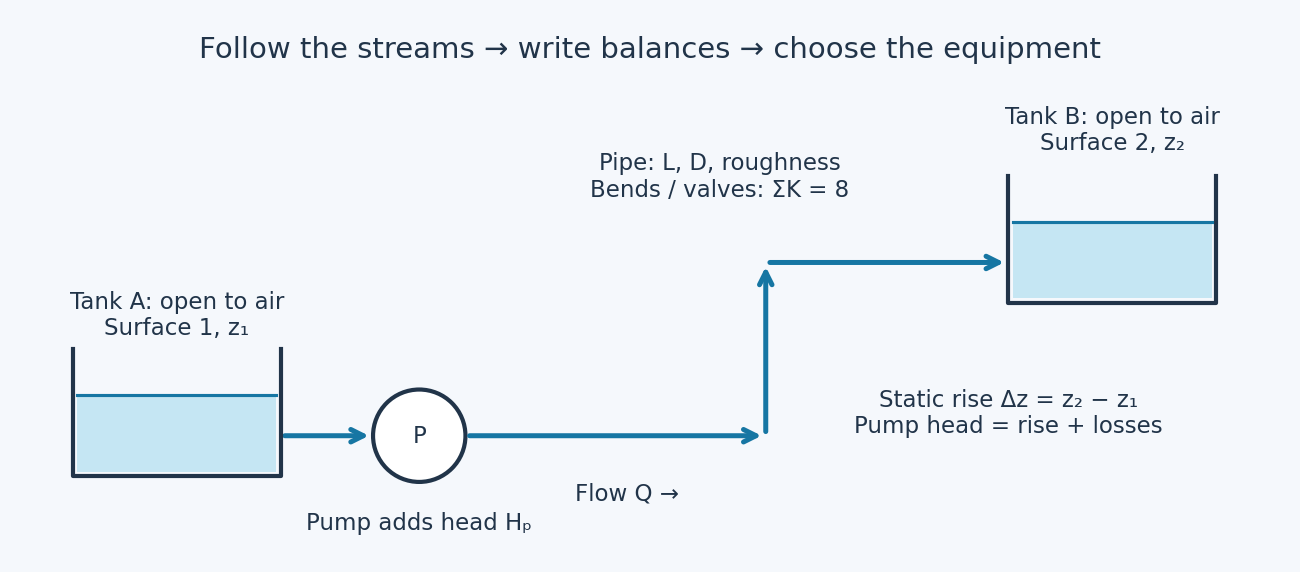

Schematic only: equipment sizes, heights and pipe lengths are not to scale.
Trace each stream with your finger. Identify what enters, what leaves, and where
energy is added or removed. Match the labels to the variables in the model below.

## Model and assumptions

The system transfers water between large open tanks. Flow is steady and
incompressible; tank-surface velocities are negligible. Pipe length is 120 m,
water density 998 kg/m³ and viscosity 0.001 Pa s; roughness is 0.000045 m.
The base elevation rise is 12 m. The combined dimensionless coefficient for
**bends and valves has been determined to be $\sum K=8$**, based on pipe velocity.

$$
v=\frac{4Q}{\pi D^2},\qquad Re=\frac{\rho vD}{\mu},\qquad
H_s=\Delta z+\left(f_D\frac{L}{D}+8\right)\frac{v^2}{2g}.
$$

Use the Darcy friction factor: $64/Re$ for laminar flow and the Haaland
approximation for turbulent flow. The helper rejects transition flow.

**Synthetic pump curves, not manufacturer data.** Real pump curves are normally
established through testing. Here the reference-speed curves are assumed:

$$
H_{ref}(q)=40-1.5\times10^6q^2,\qquad
P_{shaft,ref}(q)=900+40000q.
$$

Flow $q$ is in m³/s, head in m and shaft power in W. The coefficient 40000
has units W s/m³. These illustrative curves form a consistent pair for water
of the specified density; they are not a universal pump law. Efficiency is
**derived from the two curves**, not assumed constant:

$$
\eta_p=\frac{\rho gQH_p}{P_{shaft}}.
$$

For speed ratio $s=N/N_0$, use approximate affinity scaling with $q=Q/s$:

$$
H_p(Q,s)=s^2H_{ref}(Q/s),\qquad
P_{shaft}(Q,s)=s^3P_{shaft,ref}(Q/s).
$$

The BEP is the maximum-efficiency point on these synthetic curves. For this
exercise only, assume a permitted speed ratio of **0.6–1.1** and a recommended
flow band of **0.65–1.35 times the BEP flow at the actual speed**, per pump.
These are teaching screening limits, not manufacturer-approved operating limits.
The plotted shutoff point has nonzero shaft input and zero hydraulic output;
it is not an acceptable continuous operating condition.

**Electrical energy includes motor and drive losses.** Assume motor efficiency
0.90 and drive efficiency 0.96. With total shaft power summed over running pumps:

$$
P_{electric}=\frac{\sum P_{shaft}}{\eta_m\eta_d},\qquad
E_{year}=\frac{P_{electric}}{1000}t_{hours},\qquad
e_V=\frac{P_{electric}}{3.6\times10^6Q}.
$$

The last quantity is kWh/m³. Constant motor/drive efficiencies are simplifications.
We omit cavitation/NPSH, motor and pressure ratings, transients and interconnecting
pipe losses. In pairs, pumps are identical, run at the same speed and share
flow equally in parallel; heads add in series. Passing the screening limits
does not approve procurement.

Background: [KSB characteristic curves](https://www.ksb.com/en-global/centrifugal-pump-lexicon/article/characteristic-curve-1117926)
and [affinity laws](https://www.ksb.com/en-global/centrifugal-pump-lexicon/article/pump-affinity-laws-1117584).


### Main-case input reference

| Input | Value / units | Role |
| --- | --- | --- |
| Gravity | 9.81 m/s² | Constant used in head and power conversions |
| Length / static rise | 120 / 12 m | Given base geometry |
| Base internal diameter | 0.065 m | Reference case; design alternatives 0.050, 0.065, 0.080 m |
| Density / dynamic viscosity | 998 kg/m³ / 0.001 Pa s | Constant assumed water properties |
| Roughness / total fitting K | 0.000045 m / 8 dimensionless | Supplied pipe-loss inputs |
| Fixed delivery | 0.003 m³/s = 3 L/s | Required design service, not uncontrolled flow |
| Operating time | 4000 h/year | Assumed duty duration |
| Motor / drive efficiency | 0.90 / 0.96, dimensionless | Assumed electrical conversion efficiencies |

Curve coefficients and operating limits are stated above; cost and changed-duty
inputs are supplied in their own sections. All are teaching assumptions, not
manufacturer measurements. Head, speed, efficiency, power and energy are calculated.

### Worked example: one pipe and one trial flow
Follow the diagram from Tank A through the pump and pipe to Tank B. The pump
must supply both the elevation rise and the losses. Start by testing **one** flow;
it is not yet the operating point. The code below prints each part separately.

**Supplied worked-example data (synthetic):**

| Quantity | Value | Meaning / units |
| --- | --- | --- |
| Trial flow | 3 L/s = 0.003 m³/s | Trial value, not a prescribed pump operating point |
| Internal pipe diameter | 0.065 m | Pipe flow area is πD²/4 |
| Pipe length / elevation rise | 120 m / 12 m | Distinct contributions to the energy balance |
| Water density / dynamic viscosity | 998 kg/m³ / 0.001 Pa s | Constant assumed water properties |
| Absolute roughness | 0.000045 m | Assumed pipe-wall roughness |
| Gravitational acceleration | 9.81 m/s² | Constant used to convert velocity to head |
| Total bend/valve coefficient | 8, dimensionless | Supplied combined K, based on pipe velocity |
| Reference pump curve | H0 = 40 m, a = 1.5 × 10⁶ s²/m⁵ | H = H0 − aQ² at speed ratio 1; synthetic |

For this case, the combined dimensionless loss coefficient for the bends and
valves has been determined to be **ΣK = 8**, based on the pipe velocity.
Thus `ex_fitting_loss = 8.0 * ex_v**2 / (2 * 9.81)` is their total head loss
in metres of fluid; 8 is a supplied coefficient, not a count of fittings.
At 3 L/s you should find a velocity near 0.904 m/s and a system head near 14.0 m.
The pump supplies 26.5 m, so the actual intersection should lie at a higher flow.

In [3]:
ex_Q = 3.0 / 1000  # convert L/s to m³/s before using SI equations
ex_D, ex_L, ex_rise = 0.065, 120.0, 12.0
ex_rho = 998.0  # assumed water density, kg/m³
ex_mu = 0.001  # assumed dynamic viscosity, Pa s
ex_roughness = 4.5e-5  # assumed absolute pipe roughness, m
ex_g = 9.81  # gravitational acceleration, m/s²
ex_K = 8.0  # supplied total bend/valve loss coefficient, dimensionless
ex_H0, ex_a = 40.0, 1.5e6  # synthetic reference head curve: m, s²/m⁵
ex_v = ex_Q / (np.pi * ex_D**2 / 4)
ex_Re = ex_rho * ex_v * ex_D / ex_mu
ex_f = float(h.friction_factor(ex_Re, ex_roughness / ex_D))
ex_pipe_loss = ex_f * ex_L / ex_D * ex_v**2 / (2 * ex_g)
ex_fitting_loss = ex_K * ex_v**2 / (2 * ex_g)  # head loss in m
ex_required = ex_rise + ex_pipe_loss + ex_fitting_loss
ex_available = float(h.pump_head(ex_Q, ex_H0, ex_a, speed_ratio=1.0))
print(f"Velocity = {ex_v:.3f} m/s; Re = {ex_Re:.0f}; Darcy f = {ex_f:.4f}")
print(f"Rise = {ex_rise:.2f} m; pipe loss = {ex_pipe_loss:.2f} m; fittings = {ex_fitting_loss:.2f} m")
print(f"Required = {ex_required:.2f} m; pump = {ex_available:.2f} m")
print(f"Head surplus = {ex_available-ex_required:.2f} m")

Velocity = 0.904 m/s; Re = 58647; Darcy f = 0.0223
Rise = 12.00 m; pipe loss = 1.72 m; fittings = 0.33 m
Required = 14.05 m; pump = 26.50 m
Head surplus = 12.45 m


**Try a small change:** Copy the cell and change only ex_D to 0.050 m. Predict the direction of the loss change first. Then change the trial flow to 4 L/s. Which term changes most?

Spend about 20 minutes on this example within the model-development time below. Predict → run → explain. Then move to the main case.

### Solution to the small change

The smaller pipe increases velocity and both loss contributions. The total K = 8 remains the same supplied case value.

In [4]:
for D,q in [(.065,.003),(.050,.003),(.050,.004)]:
    v = 4*q/(np.pi*D**2)
    print(f"D={D*1000:.0f} mm, Q={q*1000:.1f} L/s: v={v:.3f} m/s, fittings={8*v*v/(2*9.81):.3f} m, total head={h.system_head(q,D,120,12,4.5e-5,8):.3f} m")

D=65 mm, Q=3.0 L/s: v=0.904 m/s, fittings=0.333 m, total head=14.048 m
D=50 mm, Q=3.0 L/s: v=1.528 m/s, fittings=0.952 m, total head=19.300 m
D=50 mm, Q=4.0 L/s: v=2.037 m/s, fittings=1.692 m, total head=24.648 m


### Main design case

The next cell defines the larger case used in the assessed tasks. Example variables use `ex_` so you can rerun them without changing this case.

Reference BEP flow: 2.862 L/s
Uncontrolled base flow: 4.0346 L/s


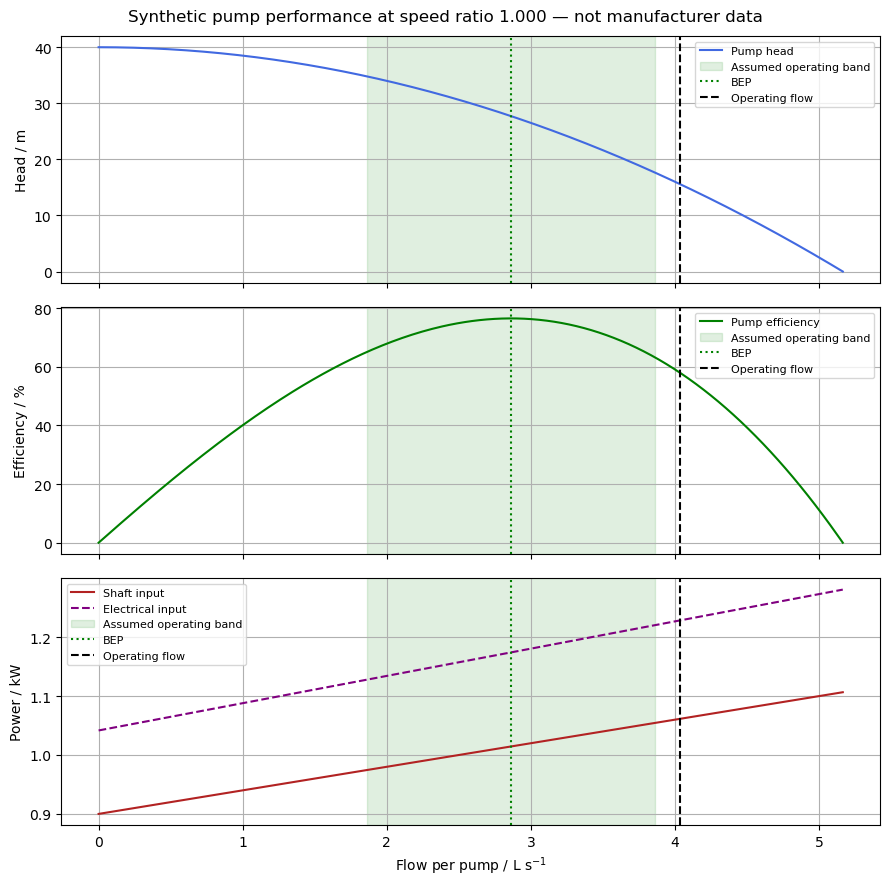

In [5]:
rho, mu, g = 998.0, .001, 9.81
length, rise, roughness, K = 120., 12., 4.5e-5, 8.
diameter = .065
base_flow = h.free_operating_point(diameter)
base_performance = h.performance(base_flow)
print(f"Reference BEP flow: {h.BEP_FLOW*1000:.3f} L/s")
print(f"Uncontrolled base flow: {base_flow*1000:.4f} L/s")
h.plot_performance(operating_flow=base_flow)
plt.show()

## 2. Read the performance curves and check the energy balance — 60 minutes


Read the three aligned performance plots: blue head, green efficiency, red shaft
input and dashed electrical input. The shaded band is an assumed per-pump
operating range. Identify the BEP and determine whether the uncontrolled base
point lies within it. A hydraulic intersection can exist outside this band.

Hand-check velocity and fitting head loss at 3 L/s. Then explain hydraulic,
shaft and electrical power at the uncontrolled operating point. Check the
efficiency identity and convert power to annual energy at 4000 h/year.
Why is zero-flow shaft power nonzero? Why must we not extrapolate to negative
head? Identify which numbers are measured data and which are assumed here.

At 3 L/s: v=0.90408 m/s; fitting loss=0.33327 m
Uncontrolled flow=4.03456 L/s; head=15.58350 m
Pump efficiency=57.995%; in assumed band=False
Hydraulic=615.55 W; shaft=1061.38 W; electrical=1228.45 W
Annual electrical energy=4913.81 kWh
Shutoff shaft input=900.0 W (not an allowed duty)


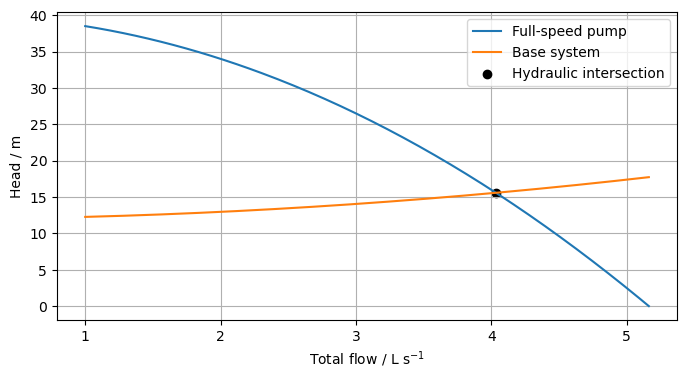

In [6]:
#@title SUPPLIED ANALYSIS — run without edits

trial_q = .003
v = 4*trial_q/(np.pi*diameter**2)
fitting_loss = 8*v*v/(2*g)
point = base_performance
print(f"At 3 L/s: v={v:.5f} m/s; fitting loss={fitting_loss:.5f} m")
print(f"Uncontrolled flow={base_flow*1000:.5f} L/s; head={point['head']:.5f} m")
print(f"Pump efficiency={point['efficiency']*100:.3f}%; in assumed band={bool(point['recommended'])}")
print(f"Hydraulic={point['hydraulic']:.2f} W; shaft={point['shaft']:.2f} W; electrical={point['electrical']:.2f} W")
print(f"Annual electrical energy={point['electrical']/1000*4000:.2f} kWh")
assert np.isclose(point['hydraulic'], point['efficiency']*point['shaft'])
assert point['electrical'] > point['shaft'] >= point['hydraulic']
print(f"Shutoff shaft input={h.performance(0)['shaft']:.1f} W (not an allowed duty)")
q_plot = np.linspace(.001,h.RUNOUT_FLOW,180)
plt.figure(figsize=(8,4))
plt.plot(q_plot*1000,h.pump_head(q_plot),label='Full-speed pump')
plt.plot(q_plot*1000,h.system_head(q_plot,diameter,120,12,roughness,8),label='Base system')
plt.scatter([base_flow*1000],[point['head']],color='black',label='Hydraulic intersection')
plt.xlabel('Total flow / L s$^{-1}$'); plt.ylabel('Head / m'); plt.legend(); plt.grid(); plt.show()

**Answers to the design questions — default settings**


**Hand check and system boundary.** At 3 L/s in the 65 mm pipe,
$v=0.003/[\pi(0.065)^2/4]=0.90408$ m/s. With the determined total K = 8,
fitting head loss is $8v^2/(2g)=0.33327$ m. The 12 m elevation rise is
stored gravitational energy, whereas pipe and fitting losses are dissipation.
Both free surfaces are open to air, so their pressures cancel in Bernoulli.

**Reading the curves.** The synthetic reference BEP is about 2.862 L/s.
The assumed reference-speed operating band is approximately 1.860–3.864 L/s.
The uncontrolled hydraulic intersection is 4.03456 L/s at 15.5835 m, outside
that band despite satisfying the head balance. Existence of an intersection
does not establish an acceptable equipment duty.

**Energy accounting.** At that intersection the water receives 615.55 W,
the pump shaft requires 1061.38 W, and electrical input is 1228.45 W after
motor and drive efficiencies of 0.90 and 0.96. Their identity is
$615.55=0.57995(1061.38)$ W. Running 4000 h uses about **4913.81 kWh of
electricity**. This replaces the old constant-70%-efficiency shaft-energy
estimate; the former 3517 kWh figure is not the electrical result in this edition.

**Shutoff and domain.** At zero flow the synthetic shaft input is 900 W,
but hydraulic output and efficiency are zero: the input is not useful delivery.
Shutoff is not an allowed continuous duty here. Negative head beyond the
curve's runout would be extrapolation outside the model, so performance
calculations reject it. None of the supplied performance curves or operating
limits is measured manufacturer data; those would be needed for a real selection.

## 3. Compare pipe diameters at the same delivery — 75 minutes


The base requirement is **exactly 3 L/s**, delivered for 4000 h/year. A variable-
speed drive adjusts speed to meet that flow without throttling. Run the supplied
table for 50, 65 and 80 mm internal diameters. For each, check required speed,
efficiency, electrical power, kWh/m³ and the assumed operating limits.

Select a diameter and report why it passes or fails. Does lower friction always
mean higher pump efficiency? Compare electricity at equal annual volume, not
uncontrolled flows. Inspect the selected-speed diagram and identify its BEP
relative to the actual operating point. Speed and each pump's flow must be
checked together. Do not change pipe roughness or fitting K between candidates.

In [7]:
#@title DESIGN SETTINGS
required_flow_Lps = 3.0 #@param {type:"number"}
operating_hours = 4000 #@param {type:"number"}
selected_diameter = 0.050 #@param [0.05, 0.065, 0.08] {type:"raw"}

D/mm  speed   eta/%   electric/W  kWh/m³   annual/kWh  speed OK  band OK
  50  0.9055   73.94     887.37  0.082164    3549.47  True  True
  65  0.8299   69.11     691.02  0.063983    2764.07  True  True
  80  0.8103   67.22     645.32  0.059752    2581.29  True  True
Chosen diameter: 50 mm; feasible under supplied limits=True
Annual delivered volume: 43200.0 m³


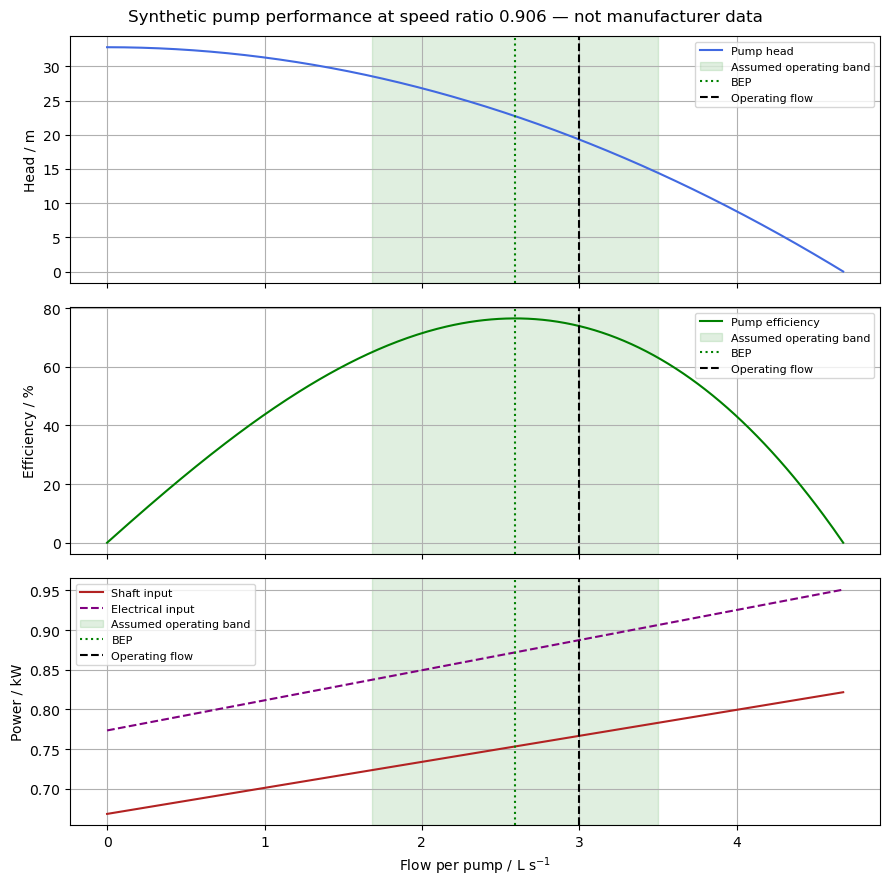

In [8]:
#@title SUPPLIED ANALYSIS — run without edits

required_flow = required_flow_Lps/1000
diameters = [.050,.065,.080]
designs = [h.design_at_flow(required_flow,D,hours=operating_hours) for D in diameters]
print('D/mm  speed   eta/%   electric/W  kWh/m³   annual/kWh  speed OK  band OK')
for D,row in zip(diameters,designs):
    print(f"{D*1000:4.0f}  {row['speed']:.4f}  {row['efficiency']*100:6.2f}  {row['electrical']:9.2f}  {row['specific_kwh']:.6f} {row['annual_kwh']:10.2f}  {row['speed_ok']}  {row['range_ok']}")
chosen = h.design_at_flow(required_flow,selected_diameter,hours=operating_hours)
print(f"Chosen diameter: {selected_diameter*1000:.0f} mm; feasible under supplied limits={chosen['feasible']}")
print(f"Annual delivered volume: {required_flow*3600*operating_hours:.1f} m³")
assert all(np.isclose(h.arrangement_head(required_flow,row['speed']),row['head']) for row in designs)
h.plot_performance(chosen['speed'],required_flow); plt.show()

**Answers to the design questions — default settings**


**Fair comparison.** Each pipe delivers exactly 3 L/s and 43200 m³/year.
Speed is adjusted to match system head rather than leaving each candidate
at a different uncontrolled throughput. The required speeds for 50, 65 and
80 mm are approximately 0.9055, 0.8299 and 0.8103. All three pass the
assumed speed and per-pump BEP-band checks at the default duty.

**Energy and efficiency.** The respective pump efficiencies are 73.94%,
69.11% and 67.22%; electrical inputs are 887.37, 691.02 and 645.32 W.
Annual electricity use is 3549.47, 2764.07 and 2581.29 kWh, or
0.082164, 0.063983 and 0.059752 kWh/m³. The 80 mm pipe minimizes
electricity among the three candidates at this fixed duty.

**Why is efficiency lower in the larger pipe?** Lower loss allows lower speed.
At unchanged delivery, that changes Q/s and moves the pump relative to the
scaled BEP. At the 50 mm candidate's speed, the BEP is about 2.59 L/s;
the actual 3 L/s point is to its right but within the assumed band. Lower
friction therefore does not automatically imply higher pump efficiency.
Here electrical demand still falls because the reduction in required hydraulic
head outweighs the efficiency reduction.

**Provisional selection.** I keep the default 50 mm candidate for the subsequent
cost comparison, while recording that 80 mm is the energy-only preference.
This is not an energy optimum at 50 mm: it is an explicit distinction between
capacity feasibility, minimum electricity and the economic criterion considered next.

## 4. Choose an energy or lifecycle design — 90 minutes


Use these **illustrative installed pipe costs** for the complete 120 m line:
50 mm €6000, 65 mm €8500, 80 mm €12000. They are supplied teaching inputs,
not quotations. Pump and drive purchase costs are common to these three single-
pump options and omitted from this incremental comparison. Use electricity
€0.20/kWh, ten years, and no discounting, maintenance or residual value.

Compare installed pipe cost plus electricity over that horizon. Select a
feasible diameter on total cost, and compare it with the least-electricity
candidate. Does the answer change at electricity €0.10 or €0.40/kWh?
Calculate the payback of a larger pipe where electricity savings are positive;
if savings are negative, report no energy payback. Explain why this simplified
cost model is not a procurement estimate.

For your selected diameter, inspect the supplied roughness sweep at fixed flow.
Is the required speed and pump operating band still acceptable? State the
remaining electrical-power and cost assumptions that matter to your choice.

In [9]:
#@title DESIGN SETTINGS
electricity_price = 0.20 #@param {type:"number"}
years = 10 #@param {type:"number"}

D/mm  pipe/€  electricity/€  total/€  eligible
  50     6000       7098.94  13098.94 True
  65     8500       5528.14  14028.14 True
  80    12000       5162.57  17162.57 True
Least cost: 50 mm; least electricity: 80 mm
At €0.10/kWh: least-cost feasible pipe 50 mm
At €0.20/kWh: least-cost feasible pipe 50 mm
At €0.40/kWh: least-cost feasible pipe 65 mm
50→65 mm: simple payback 15.92 years
65→80 mm: simple payback 95.74 years
50→80 mm: simple payback 30.99 years


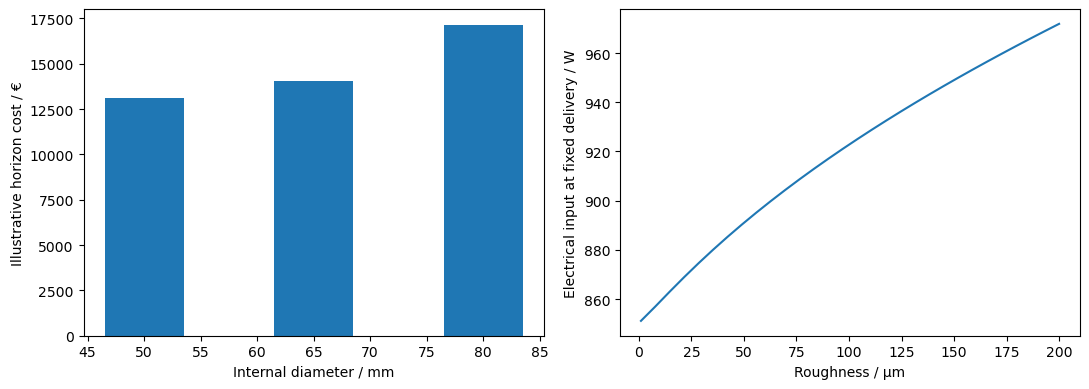

Selected pipe feasible throughout roughness sweep: True


In [10]:
#@title SUPPLIED ANALYSIS — run without edits

pipe_costs = np.array([6000.,8500.,12000.])
annual_energy = np.array([row['annual_kwh'] for row in designs])
totals = pipe_costs+electricity_price*years*annual_energy
feasible_mask = np.array([row['feasible'] for row in designs])
print('D/mm  pipe/€  electricity/€  total/€  eligible')
for D,cost,energy,total,ok in zip(diameters,pipe_costs,annual_energy,totals,feasible_mask):
    print(f'{D*1000:4.0f}  {cost:7.0f} {electricity_price*years*energy:13.2f} {total:9.2f} {ok}')
if np.any(feasible_mask):
    best_index = int(np.argmin(np.where(feasible_mask,totals,np.inf)))
    energy_index = int(np.argmin(np.where(feasible_mask,annual_energy,np.inf)))
    print(f'Least cost: {diameters[best_index]*1000:.0f} mm; least electricity: {diameters[energy_index]*1000:.0f} mm')
else:
    best_index = None
    print('No feasible candidate at this duty; do not select on cost alone.')
for price in [.10,.20,.40]:
    costs = pipe_costs+price*years*annual_energy
    if np.any(feasible_mask):
        idx = int(np.argmin(np.where(feasible_mask,costs,np.inf)))
        print(f'At €{price:.2f}/kWh: least-cost feasible pipe {diameters[idx]*1000:.0f} mm')
for small,large in [(0,1),(1,2),(0,2)]:
    savings = electricity_price*(annual_energy[small]-annual_energy[large])
    if savings > 0:
        print(f'{diameters[small]*1000:.0f}→{diameters[large]*1000:.0f} mm: simple payback {(pipe_costs[large]-pipe_costs[small])/savings:.2f} years')
    else:
        print('No positive electricity savings; no energy payback')
fig,axes = plt.subplots(1,2,figsize=(11,4))
axes[0].bar(np.array(diameters)*1000,totals,width=7)
axes[0].set(xlabel='Internal diameter / mm',ylabel='Illustrative horizon cost / €')
roughness_values = np.linspace(1e-6,2e-4,30)
rough_results = [h.design_at_flow(required_flow,selected_diameter,roughness=e,hours=operating_hours) for e in roughness_values]
axes[1].plot(roughness_values*1e6,[row['electrical'] for row in rough_results])
axes[1].set(xlabel='Roughness / µm',ylabel='Electrical input at fixed delivery / W')
plt.tight_layout(); plt.show()
print('Selected pipe feasible throughout roughness sweep:',all(row['feasible'] for row in rough_results))

**Answers to the design questions — default settings**


**Cost criterion.** Over ten undiscounted years at €0.20/kWh, installed pipe
plus electricity totals are about €13098.94 for 50 mm, €14028.14 for
65 mm and €17162.57 for 80 mm. All are screened feasible, so the **50 mm
pipe is the least-cost choice** under these inputs. The 80 mm pipe remains
the least-electricity choice. Those are different objectives.

**Price sensitivity and payback.** At €0.10/kWh, 50 mm still wins; at
€0.40/kWh, 65 mm wins. At the default price the 50-to-65 mm upgrade saves
about 785.40 kWh/year, or €157.08/year, against €2500 additional pipe
cost: simple payback is about **15.92 years**, longer than the ten-year horizon.
The 65-to-80 mm upgrade pays back in about 95.74 years; the direct
50-to-80 mm upgrade in about 30.99 years. These are undiscounted paybacks,
not investment returns. Infeasible candidates must be excluded regardless of cost.

**Robustness.** The selected default 50 mm pipe stays within the assumed
speed and operating band throughout the supplied roughness sweep at fixed
3 L/s. Increasing roughness requires more head and a revised speed;
the flow is held by control rather than allowed to drift. Check both limits
after every such adjustment, not simply the increase in electrical power.

**Limits of the cost result.** Pipe costs and electricity price are illustrative.
Common pump/drive purchase cost is excluded only for this same-pump comparison.
Real installation quotes, finance/discounting, maintenance, availability,
motor/drive efficiency maps, ageing and validated pump data could change the
choice. These totals are a teaching lifecycle comparison, not procurement estimates.

## 5. Choose single, series or parallel pumps — 60 minutes


This is a **core design challenge**. Take a 10-minute break within this block.
Keep the 80 mm line and the same pump type. Compare three arrangements at
exactly the required delivery using speed control: one pump, two identical pumps
in series, and two identical pumps in parallel. Count both running motors.

**Duty A:** 6 L/s against a 12 m elevation rise. **Duty B:** 3 L/s against
a 55 m rise. These are two separate changed requirements, not simultaneous duties.
Use the supplied diagrams and tables to decide which arrangements satisfy speed
and per-pump operating-band limits. Explain why heads add in series and flows
add in parallel, and why neither arrangement guarantees an acceptable point.
Report total electrical input and energy per volume for feasible candidates.
Do not compare arrangements by each pump's power alone.

Would two parallel pumps double uncontrolled flow in the original line? Use the
printed equal-speed intersection comparison. List at least three missing checks
before specifying an actual paired installation: suction/NPSH, casing pressure,
motor ratings, connecting pipe losses, valves, control or transients.

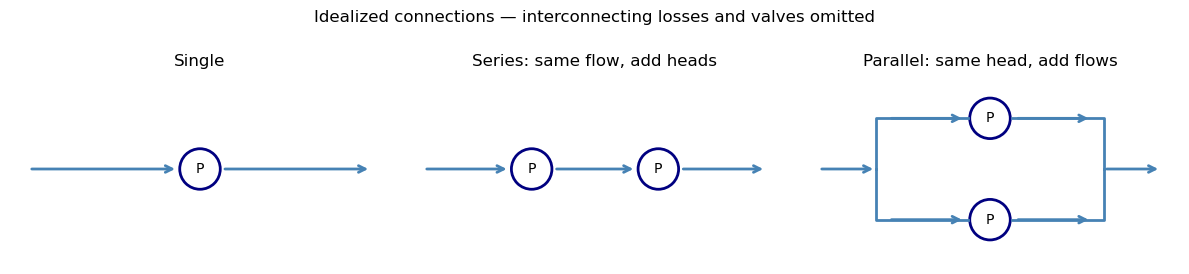


Duty A: 6.0 L/s, static rise 12.0 m
single  : speed=1.3116, each Q=6.00 L/s, eta=35.60%, total electric=2828.00 W, eV=0.130926 kWh/m³, feasible=False (speed=False, band=False)
series  : speed=1.2390, each Q=6.00 L/s, eta=20.91%, total electric=4815.29 W, eV=0.222930 kWh/m³, feasible=False (speed=False, band=False)
parallel: speed=0.8413, each Q=3.00 L/s, eta=70.07%, total electric=1436.91 W, eV=0.066523 kWh/m³, feasible=True (speed=True, band=True)

Duty B: 3.0 L/s, static rise 55.0 m
single  : speed=1.3159, each Q=3.00 L/s, eta=72.52%, total electric=2613.92 W, eV=0.242029 kWh/m³, feasible=False (speed=False, band=True)
series  : speed=1.0171, each Q=3.00 L/s, eta=76.45%, total electric=2479.49 W, eV=0.229583 kWh/m³, feasible=True (speed=True, band=True)
parallel: speed=1.2159, each Q=1.50 L/s, eta=47.99%, total electric=3950.33 W, eV=0.365771 kWh/m³, feasible=False (speed=False, band=False)


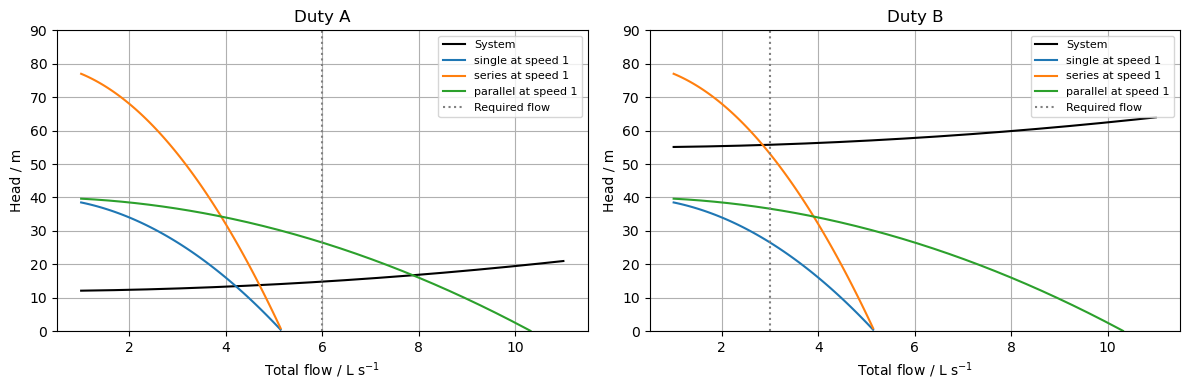

Original 65 mm line, speed 1: single=4.0346 L/s; parallel=6.9196 L/s; twice single=8.0691 L/s


In [11]:
#@title SUPPLIED ANALYSIS — run without edits

arrangement_results = {}
h.plot_arrangements(); plt.show()
for name,flow,target_rise in [('A',.006,12.),('B',.003,55.)]:
    print()
    print(f'Duty {name}: {flow*1000:.1f} L/s, static rise {target_rise:.1f} m')
    for arrangement in ['single','series','parallel']:
        row = h.design_at_flow(flow,.080,target_rise,arrangement,hours=operating_hours)
        arrangement_results[(name,arrangement)] = row
        print(f"{arrangement:8s}: speed={row['speed']:.4f}, each Q={row['pump_flow']*1000:.2f} L/s, eta={row['efficiency']*100:.2f}%, total electric={row['electrical']:.2f} W, eV={row['specific_kwh']:.6f} kWh/m³, feasible={row['feasible']} (speed={row['speed_ok']}, band={row['range_ok']})")
fig,axes = plt.subplots(1,2,figsize=(12,4))
for axis,(name,flow,target_rise) in zip(axes,[('A',.006,12.),('B',.003,55.)]):
    q = np.linspace(.001,.011,250)
    axis.plot(q*1000,h.system_head(q,.080,120,target_rise,roughness,8),color='black',label='System')
    for arrangement in ['single','series','parallel']:
        head = h.arrangement_head(q,1.,arrangement)
        axis.plot(q[head>=0]*1000,head[head>=0],label=arrangement+' at speed 1')
    axis.axvline(flow*1000,color='grey',linestyle=':',label='Required flow')
    axis.set(xlabel='Total flow / L s$^{-1}$',ylabel='Head / m',ylim=(0,90),title=f'Duty {name}')
    axis.legend(fontsize=8); axis.grid()
plt.tight_layout(); plt.show()
single_free = h.free_operating_point(.065)
parallel_free = h.free_operating_point(.065,arrangement='parallel')
print(f'Original 65 mm line, speed 1: single={single_free*1000:.4f} L/s; parallel={parallel_free*1000:.4f} L/s; twice single={single_free*2000:.4f} L/s')
assert single_free < parallel_free < 2*single_free

**Answers to the design questions — default settings**


**Duty A: 6 L/s, 12 m rise.** Two parallel pumps are the only feasible
arrangement among the supplied choices. Each carries 3 L/s at speed ratio
0.8413 and about 70.07% pump efficiency. Both motors together require
**1436.91 W electrical**, or **0.066523 kWh/m³**. The single and series
options require speeds above 1.1 and also miss the assumed per-pump band.
Their printed powers are extrapolated screening calculations at rejected speeds,
not permissible operating recommendations.

**Duty B: 3 L/s, 55 m rise.** Two series pumps are the only screened-feasible
arrangement. Each carries the full 3 L/s, shares the required total head equally,
and runs at speed ratio 1.0171 with efficiency about 76.45%. Total electrical
input is **2479.49 W**, or **0.229583 kWh/m³**. A single pump requires
speed 1.3159, and the parallel pair requires 1.2159; both exceed the stated limit.

**Connection laws and energy.** Series pumps carry the same stream sequentially,
so their energy additions per unit weight add. Parallel pumps connect between
common suction and discharge headers, so head is shared and branch flows add.
The identical-pump assumption gives equal sharing here. In both arrangements,
sum both shaft inputs and both motor/drive losses. A useful total check is
$\rho gQH_{system}=\sum P_{hydraulic,pump}$.

**Why not twice the free flow?** At speed 1 in the original 65 mm line, one
pump gives 4.0346 L/s and two parallel pumps give 6.9196 L/s, less than
8.0691 L/s. Larger total flow raises system losses, so the new intersection
does not simply double. These uncontrolled points illustrate intersection
geometry; they are not approvals of the per-pump operating ranges.

**Before specifying a pair.** Check NPSH at each suction, casing and discharge
pressure ratings (especially the second series pump), individual motor ratings,
header and valve losses, reverse flow/check valves, controls and transients.
The illustrative pipe-cost comparison cannot rank these paired installations:
their extra pump, motor, control and connection costs were not supplied.

## 6. Engineering recommendation — 45 minutes

Write 300–500 words covering your base-duty pipe/speed choice, electrical energy,
cost criterion, one rejected alternative and robustness. Recommend arrangements
for both changed duties and identify missing procurement checks. Include evidence
from the supplied plots. A feasible screen is not a verified equipment design.
Restart and run all cells in order before submitting. Ask your partner to explain
one energy conversion and one rejected design; record any resulting revision.

### Example engineering recommendation

For the base duty of exactly 3 L/s, I recommend carrying
the 50 mm line and a single variable-speed pump at speed ratio about 0.9055
forward for further review. It meets the assumed speed and per-pump flow-band
limits and minimizes the supplied ten-year pipe-plus-electricity cost. This
recommendation is specific to the illustrative prices and constant operating duty.

At fixed delivery, the 50 mm option requires about 887.37 W electrical and
3549.47 kWh/year for 4000 operating hours. The 65 and 80 mm alternatives use
2764.07 and 2581.29 kWh/year, so increasing diameter does save electricity.
However, installed pipe plus ten-year energy costs are about €13099, €14028
and €17163 at €0.20/kWh. The larger pipes do not recover their additional
cost within this horizon. At €0.40/kWh the 65 mm option becomes preferable,
so the energy-price assumption is material.

The comparison uses equal annual delivery of 43200 m³, rather than rewarding
low-power candidates that pump less water. Efficiency is derived from the
synthetic head and shaft-power curves, and electrical input includes separate
motor and drive losses. The original full-speed 65 mm hydraulic intersection
is outside the assumed recommended band; satisfying the head balance alone
is therefore insufficient. The selected 50 mm fixed-duty candidate remains
screened feasible over the stated roughness range.

For the changed high-flow duty, 6 L/s against 12 m elevation, I recommend
the parallel pair for further assessment: it is the only screened-feasible
arrangement and uses about 1.437 kW electrical in total. For the high-head
duty, 3 L/s against 55 m rise, the series pair is the only screened-feasible
choice, using about 2.479 kW. These are distinct duties, not additional
operating points that the base single-pump system is assumed to meet.

Before purchase, obtain tested pump performance and NPSH data, actual operating
limits, motor ratings, suction conditions and pressure ratings. Include connecting
pipe losses and suitable paired-pump controls. Obtain actual installation costs
and evaluate maintenance, discounting and variable load profiles. The synthetic
curves, assumed band and simplified cost model support an internally consistent
design exercise; they do not establish a verified installation or an economic
optimum across all commercially available equipment.

**Review note:** This is an instructor model answer. The checks below document a self-review; no student peer discussion or real equipment validation is claimed.

## Optional extension

What changes if the plant has a fixed-speed drive and controls delivery by
throttling? Explain where excess head is dissipated and how the fair electrical-
energy comparison would need to change. No extra code is required.

### Extension solution

With a fixed-speed pump, a throttling valve adds resistance
until the system curve intersects the pump curve at the desired flow. The valve
dissipates excess head. At 3 L/s the full-speed pump supplies 26.5 m; a
lower-loss pipe does not by itself change that pump's head or shaft input at
the same flow. It mainly changes the valve loss needed. Speed control can
instead reduce supplied head and power, which is why the core lab specifies
it. Compare actual power curves and controls at equal delivery rather than
assuming the same savings apply to both control methods.

In [12]:
flow = .003
full_speed = h.performance(flow)
for D in [.05,.065,.08]:
    required_head = h.system_head(flow,D,120,12,4.5e-5,8)
    valve_loss = float(full_speed['head']-required_head)
    print(f"D={D*1000:.0f} mm: extra valve head={valve_loss:.3f} m; fixed-speed electrical input={full_speed['electrical']:.2f} W")

D=50 mm: extra valve head=7.200 m; fixed-speed electrical input=1180.56 W
D=65 mm: extra valve head=12.452 m; fixed-speed electrical input=1180.56 W
D=80 mm: extra valve head=13.739 m; fixed-speed electrical input=1180.56 W
